# LMS filter and ADALINE algorithm

<font color="blue">Note: In order to run this Jupyter Notebook you must create a file named `aux_functions.py` inside the folder containing this Notebook with a function named `get_fourier` developed previously.</font> 

In this first project you will implement a Least Mean Square (LMS) error filter by using the Adaptive Linear Neuron (ADALINE) algorithm. This algorithm is a class of adaptive filter used to mimic a desired filter by finding the filter coefficients that relate to producing the least mean square of the error signal (difference between the desired and the actual signal). It is a stochastic gradient descent method in that the filter is only adapted based on the error at the current time. It was invented in 1960 by Stanford University professor Bernard Widrow and his first Ph.D. student, Ted Hoff.

To fully understand the concepts of this filter I recommend you to watch the following lecture by professor Widrow:

In [1]:
from aux_functions import get_fourier
from aux_plots import plot_frequency_response

In [2]:
from IPython.display import HTML

# Youtube
HTML('<iframe width="560" height="315" \\\
     src="https://www.youtube.com/embed/hc2Zj55j1zU" \\\
     title="YouTube video player" frameborder="0" allow="accelerometer; \\\
     autoplay; clipboard-write; encrypted-media; \\\
     gyroscope; picture-in-picture" allowfullscreen></iframe>')

/home/manuel/anaconda3/envs/dsp/lib/python3.10/site-packages/IPython/core/display.py:419: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


After watching professor Widrow's lecture, you can also take a look at [this paper](https://isl.stanford.edu/~widrow/papers/j1975thecomplex.pdf) to fully understand the LMS filter and ADALINE algorithm. A good summary on how the algorithm works is presented in section 2 of [this page](https://www.clear.rice.edu/elec422/1999/nsekila/LMSAlgorithm.htm).

## Problem: Implement a LMS filter and ADALINE algorithm to find the coefficients of a Digital Filter
The main problem of this project is to implement the LMS filter and ADALINE algorithm to obtain the coefficients of a filter response $w[n]$ given the input $x[n]$ and the convolution $y[n] = x[n]*w[n]$. Since this is a supervised machine learning algorithm, you will train your model with a buffered version of the input $x[n]$ and compare your calculations with the expected outputs $y[n]$. After many iterations, you will notice that the coefficients tend to converge to the desired ones of the filter while reducing the error.

## Part 1: Defining the Algorithm
In this first part you will have to create a block diagram of the LMS filter and ADALINE algorithm based on the information given to you in the previous section, to do so, you can use any available tool that you want to create your block diagram as a png image.


Your image should be called `algorithm.png` and be saved in the folder `Images`. You can instantiate your image by adding the following code on the next block of code of this Jupyter Notebook:

``` html
<img src="Images/algorithm.png" alt="Block Diagram" width="300"/>
```

Add your image here...

## Part 2: Create a buffer of streamed data
To understand how data is processed by the filter you need to think about a buffer $Z$ that will be filled with some input data. First suppose that your buffer is of size 5 and is completely empty, for example full of zeros, and you have a vector $x$ also of size 5 with some data. Now let's see Figure 1 and understand what happens on every time step.

<img src="Images/buffer.png" alt="buffer" width="300"/>

You can see that the data inside of $Z$ is moved and there are two special cases:
1. Data inside $Z$ is fully loaded (green color).
2. Data inside $Z$ is loaded and emptied (orange and green colors)

With this image in mind, you can think that a filter processes a chunk of data given by the buffer on a specific time step instead of a recursive manner. This way you have a training data for a period of time that can be used in our LMS filter and ADALINE algorithm.

Now it is your turn to create a function called `get_buffer` that generates a buffer matrix $Z$. This buffer matrix can be in fully loaded or a loaded and emptied form.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import pickle

In [4]:
def get_buffer(x, buffer_size=5, form='fl'):
    """
    Function that generates a buffer matrix with a fully loaded or loaded and emptied form.
    Parameters: 
    x (numpy array): Array of numbers representing the input signal.
    buffer_size (int): Size of buffer.
    form (string): String that represent the form of the Z matrix. 
                   Can be 'fl' for fully loaded or 'lae' for loaded and emptied.
                   By default fully loaded is selected.
  
    Returns: 
    Z (numpy array): Matrix with a fully loaded or loaded and emptied form.
    
    """
    ### BEGIN SOLUTION
    if(form=='fl'):
        Z = np.zeros((x.shape[0],buffer_size))
        for i in range(buffer_size):
            if i==0:
                Z[i:,i] = x
            else:
                Z[i:,i] = x[:-i] 
    
    elif(form=='lae'):
        Z = np.zeros((x.shape[0]+buffer_size-1,buffer_size))

        for i in range(buffer_size):
            Z[i:x.shape[0]+i, i] = x
    else:
        raise AttributeError("Wrong type of form, supported types can be 'fl' and 'lae'")
    return Z
    ### END SOLUTION

Now test your `get_buffer` function with the following code and check if it matches your expectations.

In [5]:
with open('buffer_data.pkl', 'rb') as file:
    buffer_fl_pkl, buffer_lae_pkl = pickle.load(file)

test = np.arange(0,16)

buffer_fl = get_buffer(test, buffer_size=8, form='fl')
buffer_lae = get_buffer(test, buffer_size=4, form='lae')

print("Fully Loaded Form")
print(buffer_fl, "\n")
print("Loaded and Emptied Form")
print(buffer_lae)

assert np.allclose(buffer_fl, buffer_fl_pkl)
assert np.allclose(buffer_lae, buffer_lae_pkl)

Fully Loaded Form
[[ 0.  0.  0.  0.  0.  0.  0.  0.]
 [ 1.  0.  0.  0.  0.  0.  0.  0.]
 [ 2.  1.  0.  0.  0.  0.  0.  0.]
 [ 3.  2.  1.  0.  0.  0.  0.  0.]
 [ 4.  3.  2.  1.  0.  0.  0.  0.]
 [ 5.  4.  3.  2.  1.  0.  0.  0.]
 [ 6.  5.  4.  3.  2.  1.  0.  0.]
 [ 7.  6.  5.  4.  3.  2.  1.  0.]
 [ 8.  7.  6.  5.  4.  3.  2.  1.]
 [ 9.  8.  7.  6.  5.  4.  3.  2.]
 [10.  9.  8.  7.  6.  5.  4.  3.]
 [11. 10.  9.  8.  7.  6.  5.  4.]
 [12. 11. 10.  9.  8.  7.  6.  5.]
 [13. 12. 11. 10.  9.  8.  7.  6.]
 [14. 13. 12. 11. 10.  9.  8.  7.]
 [15. 14. 13. 12. 11. 10.  9.  8.]] 

Loaded and Emptied Form
[[ 0.  0.  0.  0.]
 [ 1.  0.  0.  0.]
 [ 2.  1.  0.  0.]
 [ 3.  2.  1.  0.]
 [ 4.  3.  2.  1.]
 [ 5.  4.  3.  2.]
 [ 6.  5.  4.  3.]
 [ 7.  6.  5.  4.]
 [ 8.  7.  6.  5.]
 [ 9.  8.  7.  6.]
 [10.  9.  8.  7.]
 [11. 10.  9.  8.]
 [12. 11. 10.  9.]
 [13. 12. 11. 10.]
 [14. 13. 12. 11.]
 [15. 14. 13. 12.]
 [ 0. 15. 14. 13.]
 [ 0.  0. 15. 14.]
 [ 0.  0.  0. 15.]]


## Part 3: Implement convolution
Now that you have a way to represent a vector $x$ as a buffer matrix $Z$ you will have to use it to implement a convolution as a matrix product between $Z$ and $w$, where $w$ is a vector of the coefficients of a filter response.

Your results should match the usage of the `numpy` function `convolve` as follows:
1. When using $Z_{lae}$ results should match `np.convolve(x, w, mode='full')`.
2. When using $Z_{fl}$ results should match `np.convolve(x, w, mode='full')[0:-w.shape[0]+1]`

In [6]:
x = np.array([-5, 1, -3, 2, 4, 0, 1, -7, 9, 3, -5, -6, 8, 4, 3, 0, 1, -4])
w = np.array([7, -3, 1, 4, -9, -2])

# Implement your Z_lae calculation
# Add your first test here: 
# Compare your get_buffer implementation and the np.convolve implementation
# Assign to conv_lae your implementation
# Assign to numpy_conv_lae the numpy implementation
### BEGIN SOLUTION
Z_lae = get_buffer(x, buffer_size=w.shape[0], form='lae') 
conv_lae = (Z_lae@w).astype('int')
numpy_conv_lae = np.convolve(x, w, mode='full')
### END SOLUTION

In [7]:
assert np.allclose(conv_lae, numpy_conv_lae)
print("Convolution using Z_lea \n {}".format(conv_lae))
print("Convolution using numpy_lea \n {}".format(numpy_conv_lae))
print("Comparison using Z_lea and numpy is same?: {} \n".format((conv_lae==numpy_conv_lae).all()))

Convolution using Z_lea 
 [-35  22 -29   4  68 -21  44 -48  45 -17 -72  73  14 -67  32  91 -34 -71
 -22  -6 -25  34   8]
Convolution using numpy_lea 
 [-35  22 -29   4  68 -21  44 -48  45 -17 -72  73  14 -67  32  91 -34 -71
 -22  -6 -25  34   8]
Comparison using Z_lea and numpy is same?: True 



In [8]:
# Implement your Z_fl calculation
# Add your second test here:
# Compare your get_buffer implementation and the np.convolve implementation
# Assign to conv_fl your implementation
# Assign to numpy_conv_fl the numpy implementation
### BEGIN SOLUTION
Z_fl = get_buffer(x, buffer_size=w.shape[0], form='fl') 
conv_fl = (Z_fl@w).astype('int')
numpy_conv_fl = np.convolve(x, w, mode='full')[0:-w.shape[0]+1]
### END SOLUTION

In [9]:
assert np.allclose(conv_fl, numpy_conv_fl)
print("Convolution using Z_fl \n {}".format(conv_fl))
print("Convolution using numpy_fl \n {}".format(numpy_conv_fl))
print("Comparison using Z_fl and numpy is same?: {}".format((conv_fl==numpy_conv_fl).all()))

Convolution using Z_fl 
 [-35  22 -29   4  68 -21  44 -48  45 -17 -72  73  14 -67  32  91 -34 -71]
Convolution using numpy_fl 
 [-35  22 -29   4  68 -21  44 -48  45 -17 -72  73  14 -67  32  91 -34 -71]
Comparison using Z_fl and numpy is same?: True


## Part 4: Implement LMS filter and ADALINE algorithm
Now it is time to implement your LMS filter and ADALINE algorithm, in order to do so you need to create a function called `adaline_filter` which takes as arguments the following values:
* `X` which is a matrix in fully loaded or loaded and emptied form.
* `w` an initial vector for the estimated filter.
* `y_hat` the expected output vector for the filter, sometimes called ground truth.
* `alpha` is the learning rate or convergence factor (step size).
* `epochs` is the number of iterations.

As outputs you will have:
* `w` which is an updated version of the initial input vector $w$.
* `loss` is an array vector that stores the mean square error loss function, MSE, for every epoch or iteration, you can read more about the MSE loss function [here](https://en.wikipedia.org/wiki/Mean_squared_error).

In [10]:
def adaline_filter(X, w, y_hat, alpha=0.0005, epochs=100):
    """
    Function that generates a buffer matrix with a fully loaded or loaded and emptied form.
    Parameters: 
    X (numpy array): Matrix in fully loaded or loaded and emptied form.
    w (numpy array): Initial vector for the estimated filter.
    y_hat (numpy array): Expected output vector for the filter, sometimes called ground truth.
    alpha (float): Learning rate or convergence factor (step size).
    epochs (int): Number of iterations.
    
    Returns:
    w (numpy array): Updated version of the initial input vector w.
    loss (numpy array): Array vector that stores the mean square error loss function for every
                        epoch or iteration.
    """
    loss = []
    for i in range(epochs):
        # Filter
        ### BEGIN SOLUTION
        y = np.sum(X*w, axis=1)
        ### END SOLUTION
        
        # Error and loss estimation
        ### BEGIN SOLUTION
        L = np.mean((y_hat - y)**2)
        #print("Loss = {}".format(L))
        loss.append(L)
        ### END SOLUTION

        # Gradient calculation
        ### BEGIN SOLUTION
        dL = -2*(y_hat - y)
        dw = X
        gradient = np.sum(dw.T*dL, axis=1)
        ### END SOLUTION
        
        # Update
        ### BEGIN SOLUTION
        w = w  - (alpha*gradient)
        ### END SOLUTION

    return w, loss

To test your algorithm an input vector `x` and the ground truth vector `y_hat` are given, you will have to estimate your `w_est` vector using the `adaline_filter` function.

In [11]:
x = np.array([1, 2, -3, 4, -6, 2, 4, -1, 7, 4, 8, 6, -1, 0, 3, -9, -7])
y_hat = np.array([4, 10, -7, 9, -23, 13, -4, 32, 12, 21, 58, 21, 18, -12, 9, -15, -45, -32, 26, 3, -14])

# Estimate your variable w_est using the adaline_filter developed before
# Remember to initialize your w vector before applying the adaline_filter.
# Set your initial vector w = [0, 0, 0, 0, 0]
### BEGIN SOLUTION
w = np.array([0, 0, 0, 0, 0])
Z = get_buffer(x, buffer_size=w.shape[0], form='lae')
w_est, loss_mse = adaline_filter(Z, w, y_hat, alpha=0.0005, epochs=100)
### END SOLUTION

Estimated w values are: [ 4.  2.  1. -3.  2.]


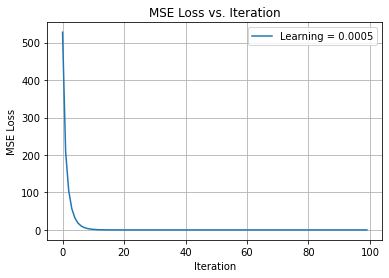

In [12]:
#Ground truth
w_hat = np.array([4, 2, 1, -3, 2])
assert np.allclose(w_est, w_hat)
print("Estimated w values are: {}".format(w_est))

plt.plot(loss_mse, label="Learning = 0.0005")
plt.title("MSE Loss vs. Iteration");
plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.grid("on")
plt.legend()
plt.show()

## Part 5: Plot Results with Different Learning Rates
In this part you will compare and plot your results by using three different learning rates `alpha` and `epochs = 200` in the same figure. For this, you need to use the following values:
* `alpha = 0.0002`
* `alpha = 0.0005`
* `alpha = 0.00006`

In [13]:
# With alpha=0.0002 assign your adaline_filter results to:
# w1 -> weight
# loss1 -> loss
### BEGIN SOLUTION
w1, loss1 = adaline_filter(Z, w, y_hat, alpha=0.0002, epochs=200)
### END SOLUTION

# With alpha=0.0005 assign your adaline_filter results to:
# w2 -> weight
# loss2 -> loss
### BEGIN SOLUTION
w2, loss2 = adaline_filter(Z, w, y_hat, alpha=0.0005, epochs=200)
### END SOLUTION

# With alpha=0.00006 assign your adaline_filter results to:
# w3 -> weight
# loss3 -> loss
### BEGIN SOLUTION
w3, loss3 = adaline_filter(Z, w, y_hat, alpha=0.00006, epochs=200)
### END SOLUTION

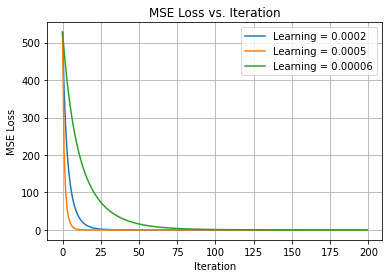

In [14]:
with open('results.pkl', 'rb') as file:
    w1_pkl, loss1_pkl, w2_pkl, loss2_pkl, w3_pkl, loss3_pkl = pickle.load(file)
    
assert np.allclose(w1_pkl, w1, atol=0.01)
assert np.allclose(loss1_pkl, loss1, atol=0.01)
assert np.allclose(w2_pkl, w2, atol=0.01)
assert np.allclose(loss2_pkl, loss2, atol=0.01)
assert np.allclose(w3_pkl, w3, atol=0.01)
assert np.allclose(loss3_pkl, loss3, atol=0.01)

plt.plot(loss1, label="Learning = 0.0002");
plt.plot(loss2, label="Learning = 0.0005");
plt.plot(loss3, label="Learning = 0.00006");
plt.title("MSE Loss vs. Iteration");
plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.grid("on")
plt.legend();

## Part 6: Apply your LMS filter and ADALINE algorithm
In this part you will use your algorithm to find the coefficients of a filter based on the expected results of the output. 
For this problem an input signal with three different tones of $30, 50$ and $150Hz$ is sampled at $800Hz$, added to the input signal there's also noise.

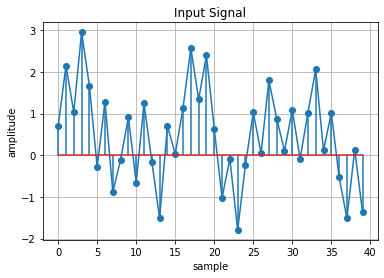

In [15]:
# Signal Generation

# Create a tone with frequency fc_1 of 50 Hz
### BEGIN SOLUTION
fc_1 = 50
### END SOLUTION

# Create a tone with frequency fc_2 of 150 Hz
### BEGIN SOLUTION
fc_2 = 150
### END SOLUTION

# Create a tone with frequency fc_3 of 30 Hz
### BEGIN SOLUTION
fc_3 = 30
### END SOLUTION

# Set a sample frequency fs of 400 Hz
### BEGIN SOLUTION
fs = 400
### END SOLUTION

# We set the time window
Ts = 1/fs
t = np.arange(0,0.10,Ts)

# We create three different signals
signal_1 = np.sin(2*np.pi*fc_1*t)
signal_2 = np.sin(2*np.pi*fc_2*t)
signal_3 = np.sin(2*np.pi*fc_3*t)

# We create a random noise signal that will be added to our model
np.random.seed(123)
noise = np.random.rand(signal_1.shape[0])

# Create an input signal x wich is the sum of the three signals and the noise
### BEGIN SOLUTION
x = signal_1 + signal_2 + signal_3 + noise
### END SOLUTION

# Our expected output signal will be the sum of signal_1, signal_2 and some extra noise
# Note that this extra noise is not the same as the one used above.
# Assign to y_hat the expected signal.
# Use a random signal with seed equal to 42.
np.random.seed(42)
noise_hat = np.random.rand(signal_1.shape[0])
y_hat = signal_1 + signal_2 + noise_hat

plt.plot(x);
plt.stem(x, use_line_collection=True);
plt.title("Input Signal");
plt.xlabel("sample")
plt.ylabel("amplitude")
plt.grid("on");

In [16]:
with open('signal_test.pkl', 'rb') as file:
    x_pkl, y_hat_pkl = pickle.load(file)

assert np.allclose(x, x_pkl, atol=0.01)
assert np.allclose(y_hat, y_hat_pkl, atol=0.01)

In this part you will use a for loop to find the filter coeffients `w` using your `adaline_filter` function. For this, you will use the signal `x` and `y_hat` from the previous part. The for loop in here will evaluate with two different number of epochs: `2` and `200`. The filter coefficents `w` will be stored in a dictionary named `W`.

In [17]:
# Set an empty dictionary and name it W
### BEGIN SOLUTION
W = {}
### END SOLUTION
for e in [2, 200]:
    # We will assume that our filter coefficients are a total of 51
    # Initialize the filter coefficients w by setting them to zero
    ### BEGIN SOLUTION
    w = np.zeros(51)
    ### END SOLUTION

    # Find the filter coefficients w using the adaline_filter function
    # Use a fl form for the get_buffer function
    # Use a value of alpha of 0.0005
    ### BEGIN SOLUTION
    Z = get_buffer(x, buffer_size=w.shape[0], form='fl')
    w, loss = adaline_filter(Z, w, y_hat, alpha=0.0005, epochs=e)
    ### END SOLUTION
    W [f'epochs={e}'] = w

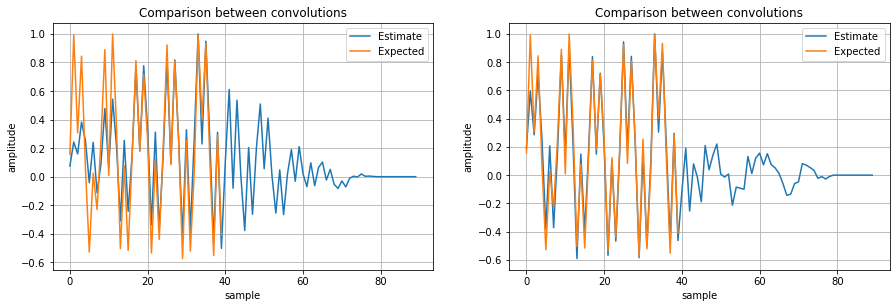

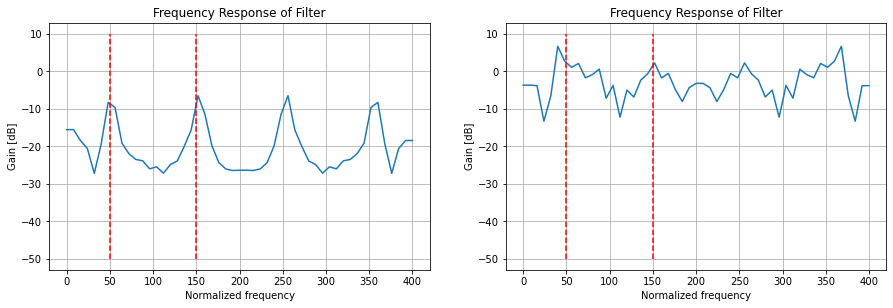

In [18]:
with open('epochs.pkl', 'rb') as file:
    W_pkl = pickle.load(file)

assert np.allclose(W_pkl['epochs=2'], W['epochs=2'], atol=0.01)
assert np.allclose(W_pkl['epochs=200'], W['epochs=200'], atol=0.01)

plt.rcParams["figure.figsize"] = (15,10)

plt.subplot(2,2,1)
conv = np.convolve(x, W['epochs=2'], mode='full')
plt.plot(conv/conv.max(), label="Estimate");
plt.plot(y_hat/y_hat.max(), label="Expected");
plt.title("Comparison between convolutions");
plt.xlabel("sample")
plt.ylabel("amplitude")
plt.legend()
plt.grid("on")

plt.subplot(2,2,2)
conv = np.convolve(x, W['epochs=200'], mode='full')
plt.plot(conv/conv.max(), label="Estimate");
plt.plot(y_hat/y_hat.max(), label="Expected");
plt.title("Comparison between convolutions");
plt.xlabel("sample")
plt.ylabel("amplitude")
plt.legend()
plt.grid("on")
plt.show()

plt.subplot(2,2,3)
W_, f_ = get_fourier(W['epochs=2'])
plot_frequency_response(W_.reshape(-1,1), f_*fs)
plt.vlines(x=fc_1, ymin=-50, ymax=10, color='red', linestyles='--')
plt.vlines(x=fc_2, ymin=-50, ymax=10, color='red', linestyles='--')

plt.subplot(2,2,4)
W_, f_ = get_fourier(W['epochs=200'])
plot_frequency_response(W_.reshape(-1,1), f_*fs)
plt.vlines(x=fc_1, ymin=-50, ymax=10, color='red', linestyles='--')
plt.vlines(x=fc_2, ymin=-50, ymax=10, color='red', linestyles='--')

plt.show()

## Part 7: Questions
* What does overfitting mean?
* What happens with the frequency and time results when you overfit your ADALINE filter?

Submit your answers here...